# 08 - Eficiência computacional

A comparação considera tempo de ajuste, inferência repetida, vazão, alocações de memória rastreadas, tamanho serializado e complexidade dos modelos. No sistema especialista, o esforço humano de elaboração é tratado separadamente do tempo computacional de inferência. Energia e emissões são estimadas a partir de uma potência de referência do notebook que utilizei, sem medição elétrica direta.

In [1]:
from pathlib import Path
import os, sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
ROOT = Path.cwd().resolve()
if not (ROOT/'data').exists(): ROOT = ROOT.parent
assert (ROOT/'src').exists(), 'Abra o notebook a partir da pasta do projeto.'
sys.path.insert(0,str(ROOT))
TAB=ROOT/'reports'/'tables'; FIG=ROOT/'reports'/'figures'
META=json.loads((ROOT/'data/processed/metadata.json').read_text(encoding='utf-8'))
print('Projeto:', ROOT)

Projeto: C:\Users\Felipe Erik\Desktop\Trabalho2IA\final\student_career_ia


## Medição da inferência
Para cada modelo treinado, o tempo médio, desvio padrão, vazão e memória alocada são estimados por repetição de inferência. O tempo de treinamento foi registrado durante o ajuste.

In [2]:
import pickle
from src.training import prepare
from src.profiling import measure_inference
medicoes_inferencia = []
for tarefa in ('regression','classification'):
    _, Xte, _, _ = prepare(tarefa)
    for nome in ('Arvore_sem_limite','Arvore_ajustada','Random_Forest','Gradient_Boosting'):
        with (ROOT/'models'/f'{tarefa}_{nome}.pkl').open('rb') as f:
            modelo = pickle.load(f)
        valores = measure_inference(modelo,Xte,repeats=30)
        medicoes_inferencia.append(dict(tarefa=tarefa,modelo=nome,**valores))
display(pd.DataFrame(medicoes_inferencia).round(5))

,tarefa,modelo,inference_mean_seconds,inference_sd_seconds,inference_per_sample_ms,throughput_samples_second,peak_tracemalloc_kb
0,regression,Arvore_sem_limite,0.13048,0.11059,0.01305,76640.42115,7561.41113
1,regression,Arvore_ajustada,0.06612,0.01747,0.00661,151232.24792,6830.68066
2,regression,Random_Forest,0.42217,0.17415,0.04222,23686.90497,6890.64355
3,regression,Gradient_Boosting,0.07474,0.02065,0.00747,133798.36292,6809.38281
4,classification,Arvore_sem_limite,0.07857,0.03606,0.00786,127280.50063,6938.52246
5,classification,Arvore_ajustada,0.07891,0.03827,0.00789,126731.35626,6961.77734
6,classification,Random_Forest,0.31358,0.12039,0.03136,31889.31059,6942.80078
7,classification,Gradient_Boosting,0.13760,0.05211,0.01376,72675.38691,7000.05566


## Medições locais disponíveis
Os dados registrados foram produzidos na execução local de 26/10/2026, no ambiente Windows com Intel Core i5-7200U e 16 GB de RAM, conforme informação do ambiente experimental. peak_tracemalloc_kb captura o pico de alocações rastreadas por Python, não é o pico total de RAM do processo. Tempos de treinamento incluem, nesta implementação, a busca de parâmetros. Essa diferença é considerada na comparação.

,task,model,train_seconds,inference_mean_seconds,inference_sd_seconds,inference_per_sample_ms,throughput_samples_second,peak_tracemalloc_kb,model_bytes,complexity
0,regression,Sistema_Especialista,NaN,0.9062,0.2239,0.0906,11034.7078,277.6484,399,"{""num_rules"": 5}"
1,regression,Arvore_sem_limite,1.1265,0.0688,0.0148,0.0069,145289.9328,6816.7402,5681345,"{""depth"": 28, ""nodes"": 78853, ""leaves"": 39427}"
2,regression,Arvore_ajustada,76.4652,0.0571,0.0106,0.0057,175008.1072,6831.2705,295875,"{""depth"": 12, ""nodes"": 4055, ""leaves"": 2028}"
3,regression,Random_Forest,221.7747,0.3203,0.1372,0.0320,31225.0587,6836.5566,131374583,"{""trees"": 100, ""total_nodes"": 1824114}"
4,regression,Gradient_Boosting,154.0503,0.0864,0.0220,0.0086,115708.9119,6854.6426,92219,"{""estimators"": 100}"
5,classification,Sistema_Especialista,NaN,0.9509,0.4615,0.0951,10516.7054,265.3359,433,"{""num_rules"": 6}"
6,classification,Arvore_sem_limite,1.1481,0.0564,0.0109,0.0056,177437.7912,6991.4512,950537,"{""depth"": 46, ""nodes"": 11831, ""leaves"": 5916}"
7,classification,Arvore_ajustada,24.0090,0.0587,0.0102,0.0059,170304.1939,6947.2207,11960,"{""depth"": 6, ""nodes"": 99, ""leaves"": 50}"
8,classification,Random_Forest,53.6509,0.1876,0.0363,0.0188,53304.7809,6955.7871,9079685,"{""trees"": 100, ""total_nodes"": 112930}"
9,classification,Gradient_Boosting,177.5365,0.0769,0.0342,0.0077,129966.6597,6991.6367,59501,"{""estimators"": 60}"


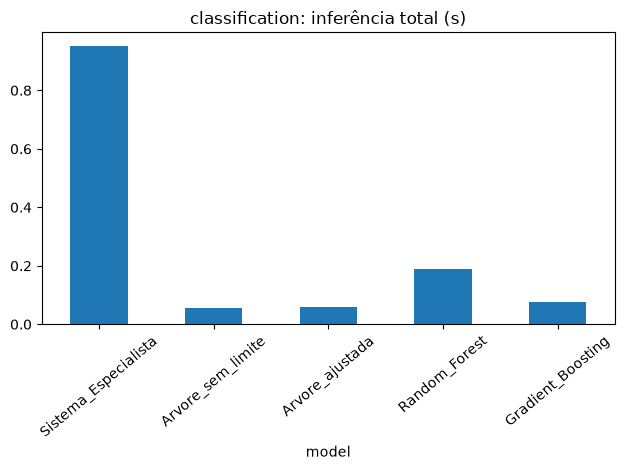

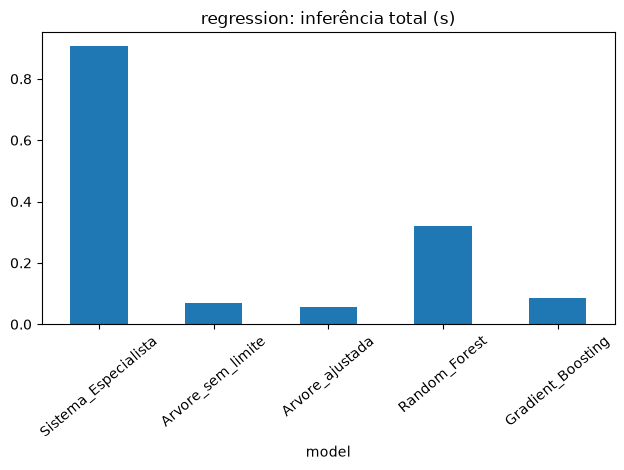

In [3]:
e=pd.read_csv(TAB/'efficiency.csv')
cols=['task','model','train_seconds','inference_mean_seconds','inference_sd_seconds','inference_per_sample_ms','throughput_samples_second','peak_tracemalloc_kb','model_bytes','complexity']
display(e[cols].round(4))
for task,d in e.groupby('task'):
    d.plot(x='model',y='inference_mean_seconds',kind='bar',title=f'{task}: inferência total (s)',legend=False,rot=40)
    plt.tight_layout();plt.show()

## Complexidade e implantação
Árvores compactas e regras simples geralmente ocupam menos espaço e podem ser candidatas para dispositivos de borda. Random Forest pode gerar artefatos maiores, servidores acomodam melhor seu custo. Essa recomendação deve levar em conta também throughput real, alocação de RAM e capacidade de manutenção.

## Estimativa de consumo de energia e emissões

O processador da máquina utilizada é um Intel Core i5-7200U, possuindo TDP nominal de 15 W, segundo a [ficha técnica da Intel](https://www.intel.com.br/content/www/br/pt/products/sku/95443/intel-core-i57200u-processor-3m-cache-up-to-3-10-ghz/specifications.html). O TDP é uma especificação térmica e não equivale à potência elétrica média medida. Neste estudo, 15 W é adotado como potência de referência para uma estimativa simplificada do consumo atribuído ao processador.

No Sistema Especialista, somente a inferência entra no cálculo. Para modelos ajustados com busca, train_seconds compreende a etapa cronometrada de ajuste, não necessariamente uma única árvore ou floresta. Não estão incluídos os demais componentes do notebook, o custo de todo o fluxo de pré-processamento nem a eletricidade do sistema inteiro.


In [4]:
import pandas as pd
energia = pd.read_csv(TAB / 'efficiency.csv')
colunas = ['task', 'model', 'train_seconds', 'inference_mean_seconds',
           'tempo_estimado_s', 'potencia_referencia_w',
           'energia_estimada_kwh', 'emissao_estimada_gco2']
display(energia[colunas].round(10))


,task,model,train_seconds,inference_mean_seconds,tempo_estimado_s,potencia_referencia_w,energia_estimada_kwh,emissao_estimada_gco2
0,regression,Sistema_Especialista,NaN,0.906232,0.906232,15,0.000004,0.000173
1,regression,Arvore_sem_limite,1.126493,0.068828,1.195321,15,0.000005,0.000228
2,regression,Arvore_ajustada,76.465205,0.057140,76.522346,15,0.000319,0.014603
3,regression,Random_Forest,221.774719,0.320256,222.094975,15,0.000925,0.042383
4,regression,Gradient_Boosting,154.050326,0.086424,154.136750,15,0.000642,0.029414
5,classification,Sistema_Especialista,NaN,0.950868,0.950868,15,0.000004,0.000181
6,classification,Arvore_sem_limite,1.148059,0.056358,1.204417,15,0.000005,0.000230
7,classification,Arvore_ajustada,24.009003,0.058718,24.067721,15,0.000100,0.004593
8,classification,Random_Forest,53.650865,0.187600,53.838465,15,0.000224,0.010274
9,classification,Gradient_Boosting,177.536512,0.076943,177.613455,15,0.000740,0.033895


## Limitações e comparação de implantação

A coluna peak_tracemalloc_kb corresponde às alocações Python rastreadas na inferência e não ao pico total de RAM (RSS). Os tempos de inferência são médias de execuções repetidas; as estimativas energéticas referem-se a um lote de inferência por modelo. Uma medição elétrica real demandaria instrumentação ou telemetria adicional. O arquivo reports/tables/efficiency.csv conserva os tempos, a vazão, o tamanho dos modelos e a complexidade de cada abordagem.

Para dispositivos com restrições de memória e processamento, o Sistema Especialista ou uma árvore compacta podem ter vantagens em tamanho e interpretabilidade, dependendo da precisão mínima requerida. Random Forest e Gradient Boosting obtiveram melhor desempenho preditivo na comparação registrada, com maior custo ou complexidade de implantação. O trade-off deve considerar tanto as métricas de desempenho quanto os tempos e os tamanhos observados.
